# RQ2 — Regime-dependent trajectory predictability

**Research question**

> Does forecast predictability differ between contrasting oceanographic regimes, particularly the Kuroshio Core and lower-energy shelf waters? Do model rankings change across regimes?

This notebook consolidates the RQ2 workflow into one readable document. It uses the frozen RQ1 test predictions and the prepared RQ2 environmental data already stored in this project.

## Main workflow

```text
Forecast origins (5,117 cases)
             │
             ├── GEBCO bathymetry → water depth
             └── GLORYS 1994–2022 climatology → mean surface current
                                  │
                                  ▼
                 Four oceanographic regimes
      Shelf | Kuroshio Core | Transition | Other Offshore
                                  │
                                  ▼
             Frozen RQ1 errors on 757 test cases
                                  │
                                  ▼
       Regime comparisons + drifter-clustered bootstrap
                                  │
                                  ▼
           Threshold sensitivity and final figures
```

**Important:** The notebook opens with the saved intermediate files, so it is immediately runnable. Raw GEBCO/GLORYS downloads and the six separate RQ1 case-metric files are not required unless the entire pipeline is rebuilt from scratch.

## 1. Setup

All paths are anchored to the project directory. Plot labels are kept in English so that Matplotlib does not produce missing-Chinese-font warnings.

In [1]:
from pathlib import Path
import os
import warnings

os.environ.setdefault("MPLCONFIGDIR", "/tmp/data3001-matplotlib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()), None)
if PROJECT is None:
    raise FileNotFoundError('Could not locate the final_submission project root.')
RQ2 = PROJECT / "RQ2"
DATA = RQ2 / "data"
FIGURES = RQ2 / "figures"

REGIMES = ["Shelf", "Kuroshio Core", "Transition", "Other Offshore"]
MODELS = ["Persistence", "Mean Flow", "Ridge", "FNN", "VAR(1)", "KNN"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Project:", PROJECT)
print("RQ2 data:", DATA)
print("RQ2 figures:", FIGURES)

Project: /Users/roger/Documents/data3001-project
RQ2 data: /Users/roger/Documents/data3001-project/RQ2/data
RQ2 figures: /Users/roger/Documents/data3001-project/RQ2/figures


## 2. Reproducibility and file availability

The RQ2 folder contains prepared environmental features, merged test errors, bootstrap summaries and final figures. The table below distinguishes files that are present from upstream files that would be needed for a complete raw-data rebuild.

In [2]:
required_files = {
    "Prepared forecast cases": PROJECT / "data/processed/forecast_origins.parquet",
    "Drifter split table": PROJECT / "data/processed/drifter_splits.csv",
    "Prepared bathymetry features": DATA / "forecast_case_bathymetry.csv",
    "GLORYS climatology": DATA / "glorys_climatology_1994_2022.nc",
    "Prepared regime labels": DATA / "forecast_case_regimes.csv",
    "Merged six-model test errors": DATA / "rq2_test_model_errors_long.csv",
    "Bootstrap summary": DATA / "rq2_cluster_bootstrap_summary.csv",
    "Raw six-model RQ1 metrics folder": PROJECT / "RQ1_GitHub/output/rq1/en",
    "Raw GEBCO folder": PROJECT / "Data/external/gebco",
    "Raw GLORYS folder": PROJECT / "Data/external/glorys",
}

availability = pd.DataFrame([
    {"Item": name, "Available": path.exists(), "Path": str(path)}
    for name, path in required_files.items()
])
display(availability.style.hide(axis="index"))

Item,Available,Path
Prepared forecast cases,True,/Users/roger/Documents/data3001-project/data/processed/forecast_origins.parquet
Drifter split table,True,/Users/roger/Documents/data3001-project/data/processed/drifter_splits.csv
Prepared bathymetry features,True,/Users/roger/Documents/data3001-project/RQ2/data/forecast_case_bathymetry.csv
GLORYS climatology,True,/Users/roger/Documents/data3001-project/RQ2/data/glorys_climatology_1994_2022.nc
Prepared regime labels,True,/Users/roger/Documents/data3001-project/RQ2/data/forecast_case_regimes.csv
Merged six-model test errors,True,/Users/roger/Documents/data3001-project/RQ2/data/rq2_test_model_errors_long.csv
Bootstrap summary,True,/Users/roger/Documents/data3001-project/RQ2/data/rq2_cluster_bootstrap_summary.csv
Raw six-model RQ1 metrics folder,False,/Users/roger/Documents/data3001-project/RQ1_GitHub/output/rq1/en
Raw GEBCO folder,False,/Users/roger/Documents/data3001-project/Data/external/gebco
Raw GLORYS folder,False,/Users/roger/Documents/data3001-project/Data/external/glorys


### What can be reproduced now?

- **Immediately reproducible:** regime summaries, model comparisons, bootstrap results, sensitivity summaries and final figures.
- **Not fully rebuildable from raw inputs in the current folder:** the original GEBCO/GLORYS downloads and the six separate RQ1 case-metric files are absent.
- The saved merged error file contains the complete six-model × 757-case data needed for the main RQ2 analysis.

## 3. Data foundation and leakage-safe partitions

The original data contain 521 assigned drifters. Only drifters that produce at least one valid 96-hour forecasting window appear in the final case table.

Each forecasting case contains:

- 24 hours of observed history;
- a forecast origin;
- 72 hours of target trajectory;
- no overlap with the next selected case in the same continuous segment.

In [3]:
origins = pd.read_parquet(PROJECT / "data/processed/forecast_origins.parquet")
splits = pd.read_csv(PROJECT / "data/processed/drifter_splits.csv")

partition_order = ["training", "calibration", "test"]
assigned = splits.groupby("partition")["ID"].nunique().reindex(partition_order)
usable_drifters = origins.groupby("partition")["ID"].nunique().reindex(partition_order)
cases = origins.groupby("partition")["forecast_case_id"].size().reindex(partition_order)

partition_summary = pd.DataFrame({
    "Assigned drifters": assigned,
    "Drifters with usable cases": usable_drifters,
    "Forecast cases": cases,
})
partition_summary.loc["Total"] = partition_summary.sum()
display(partition_summary.astype(int))

leakage_check = origins.groupby("ID")["partition"].nunique().max()
print(f"Maximum partitions occupied by one drifter: {leakage_check}")
assert leakage_check == 1
assert len(origins) == 5117

,Assigned drifters,Drifters with usable cases,Forecast cases
partition,,,
training,364,311,3591
calibration,78,66,769
test,79,71,757
Total,521,448,5117


Maximum partitions occupied by one drifter: 1


**Why 79 and 71 are both correct:** 79 physical drifters were assigned to the test partition, but only 71 generated at least one usable forecast case. RQ2 therefore evaluates **757 cases from 71 usable test drifters**.

## 4. Environmental features used to define regimes

### Bathymetry

GEBCO elevation is matched to each forecast origin and converted into positive water depth.

### Surface-current climatology

Monthly GLORYS surface-current components from 1994–2022 are averaged:

\[
ar u(\lambda,\phi)=rac{1}{T}\sum_t u_t(\lambda,\phi),\qquad
ar v(\lambda,\phi)=rac{1}{T}\sum_t v_t(\lambda,\phi),
\]

and climatological vector speed is

\[
s(\lambda,\phi)=\sqrt{ar u^2+ar v^2}.
\]

This describes a **climatological spatial regime**, not the instantaneous current on the forecast date.

**GLORYS 1994–2022 mean surface-current climatology**

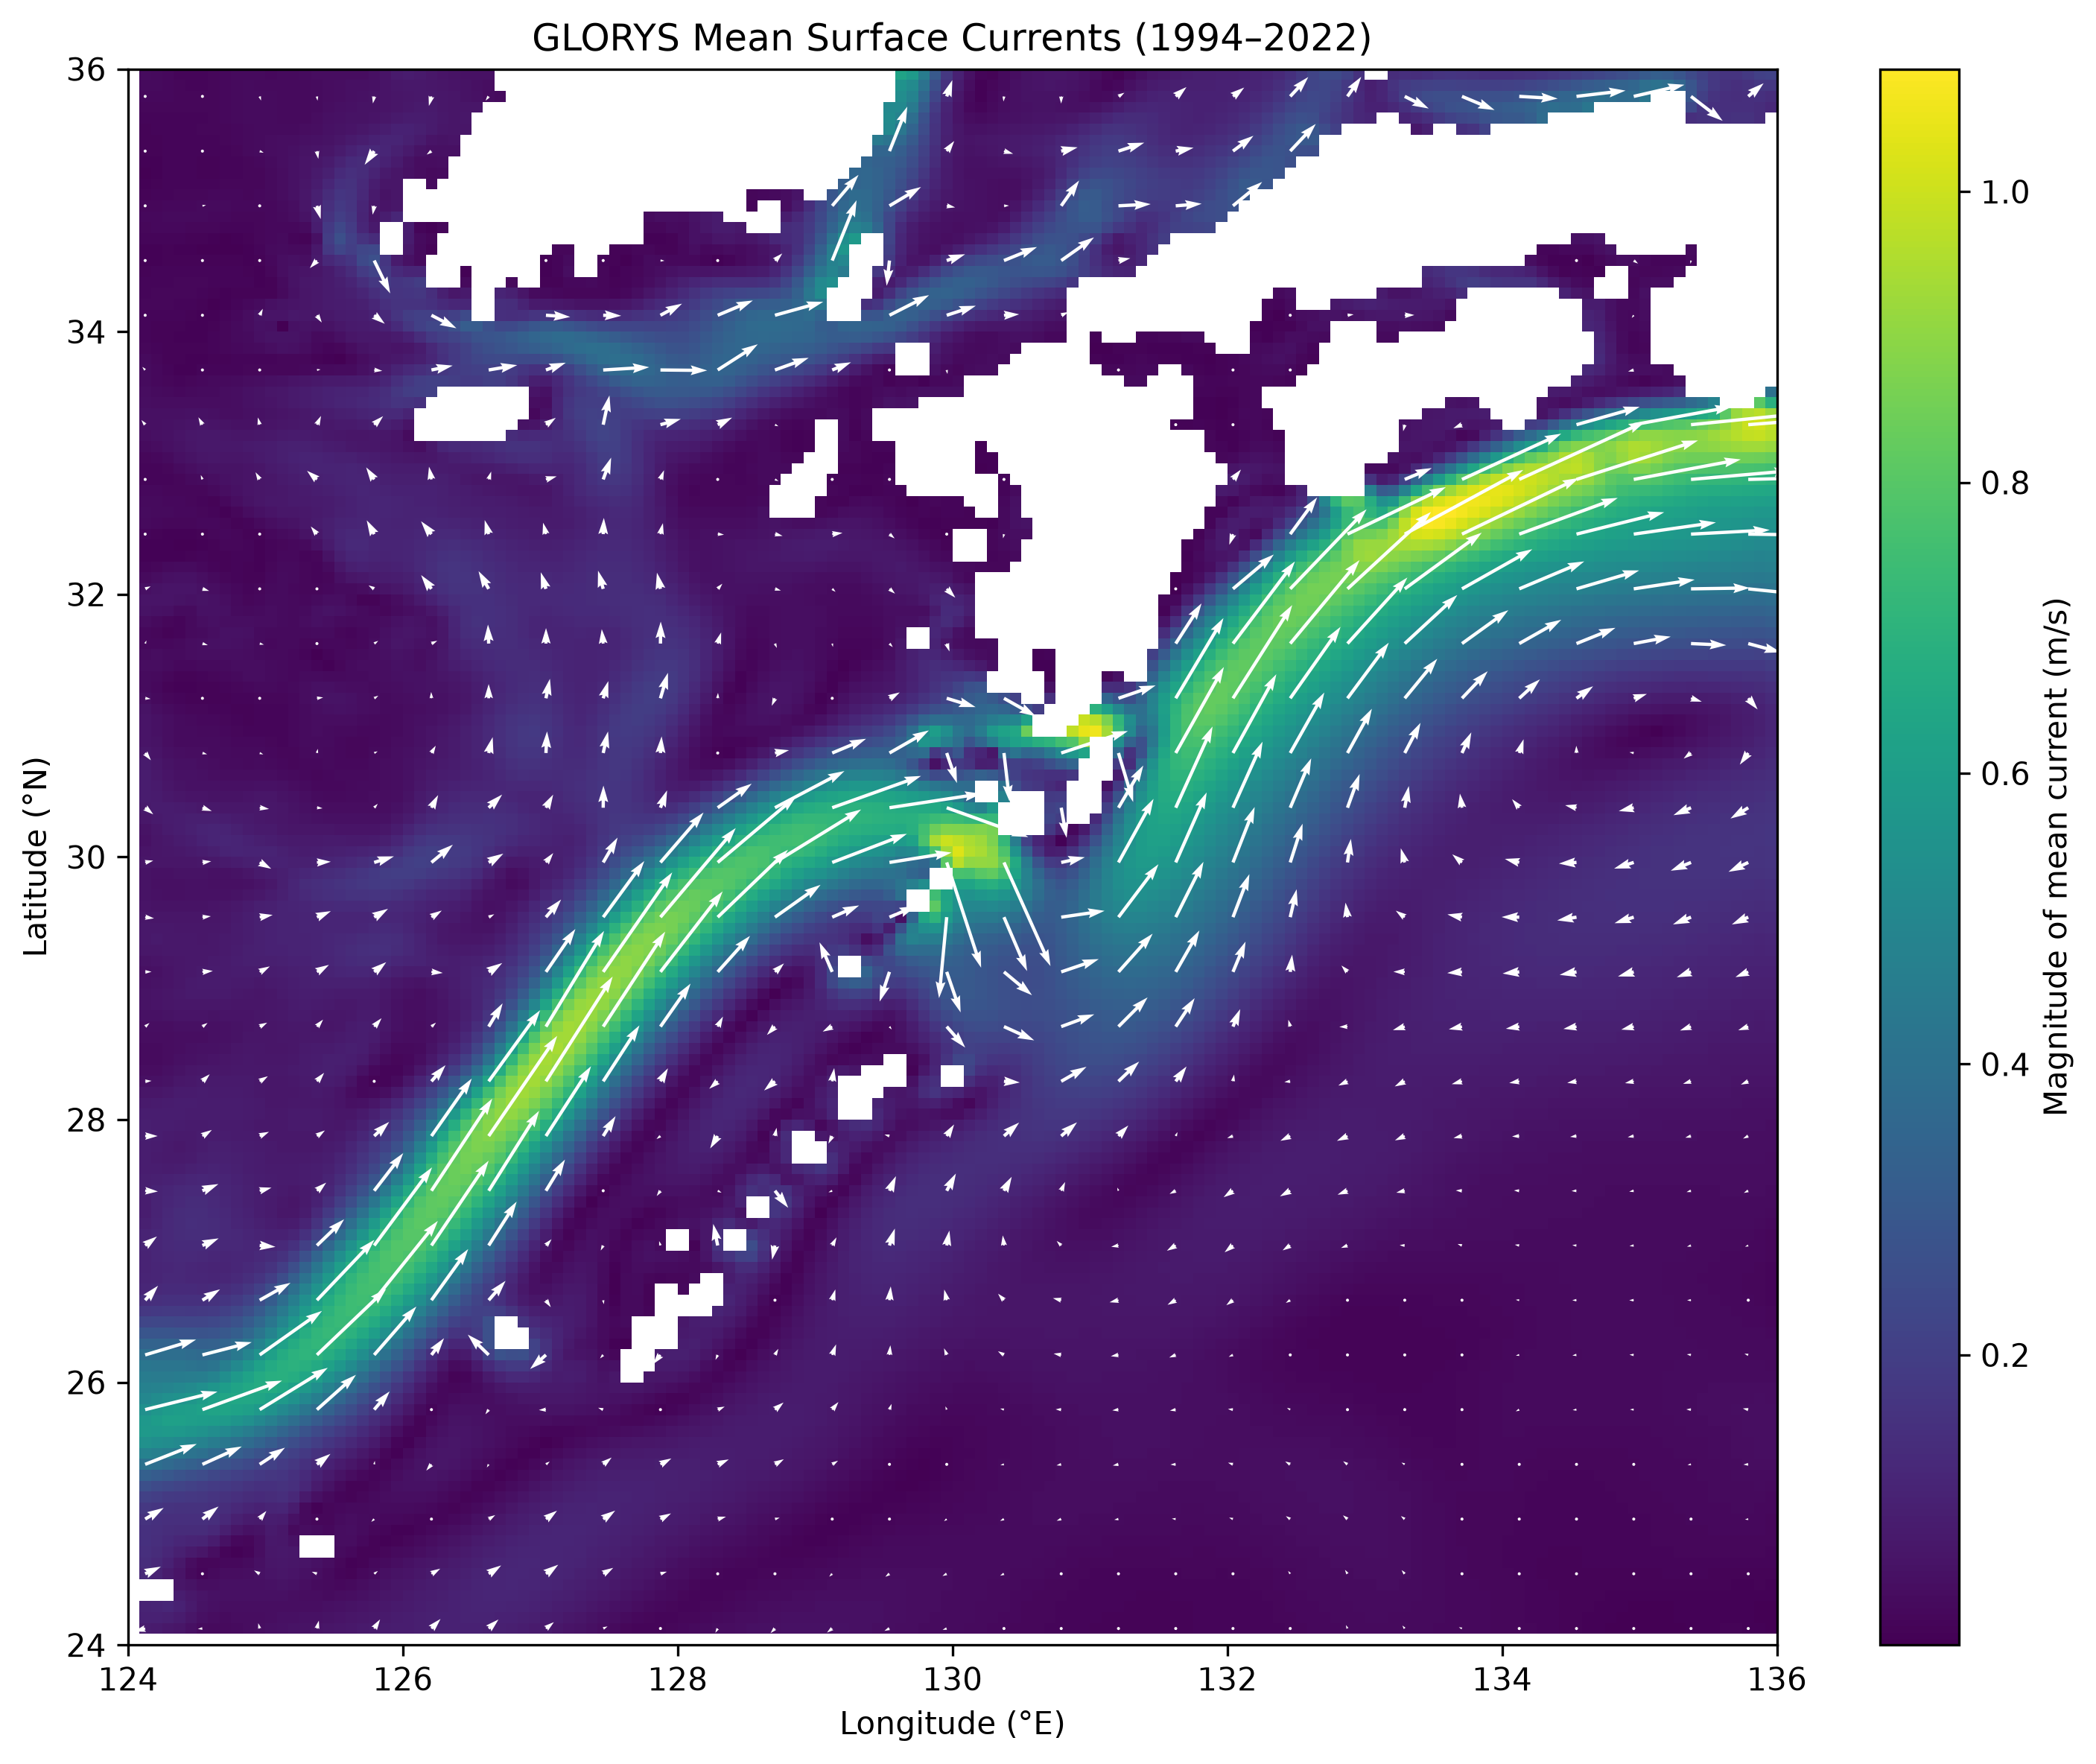

**Bathymetry and climatological-current overlay**

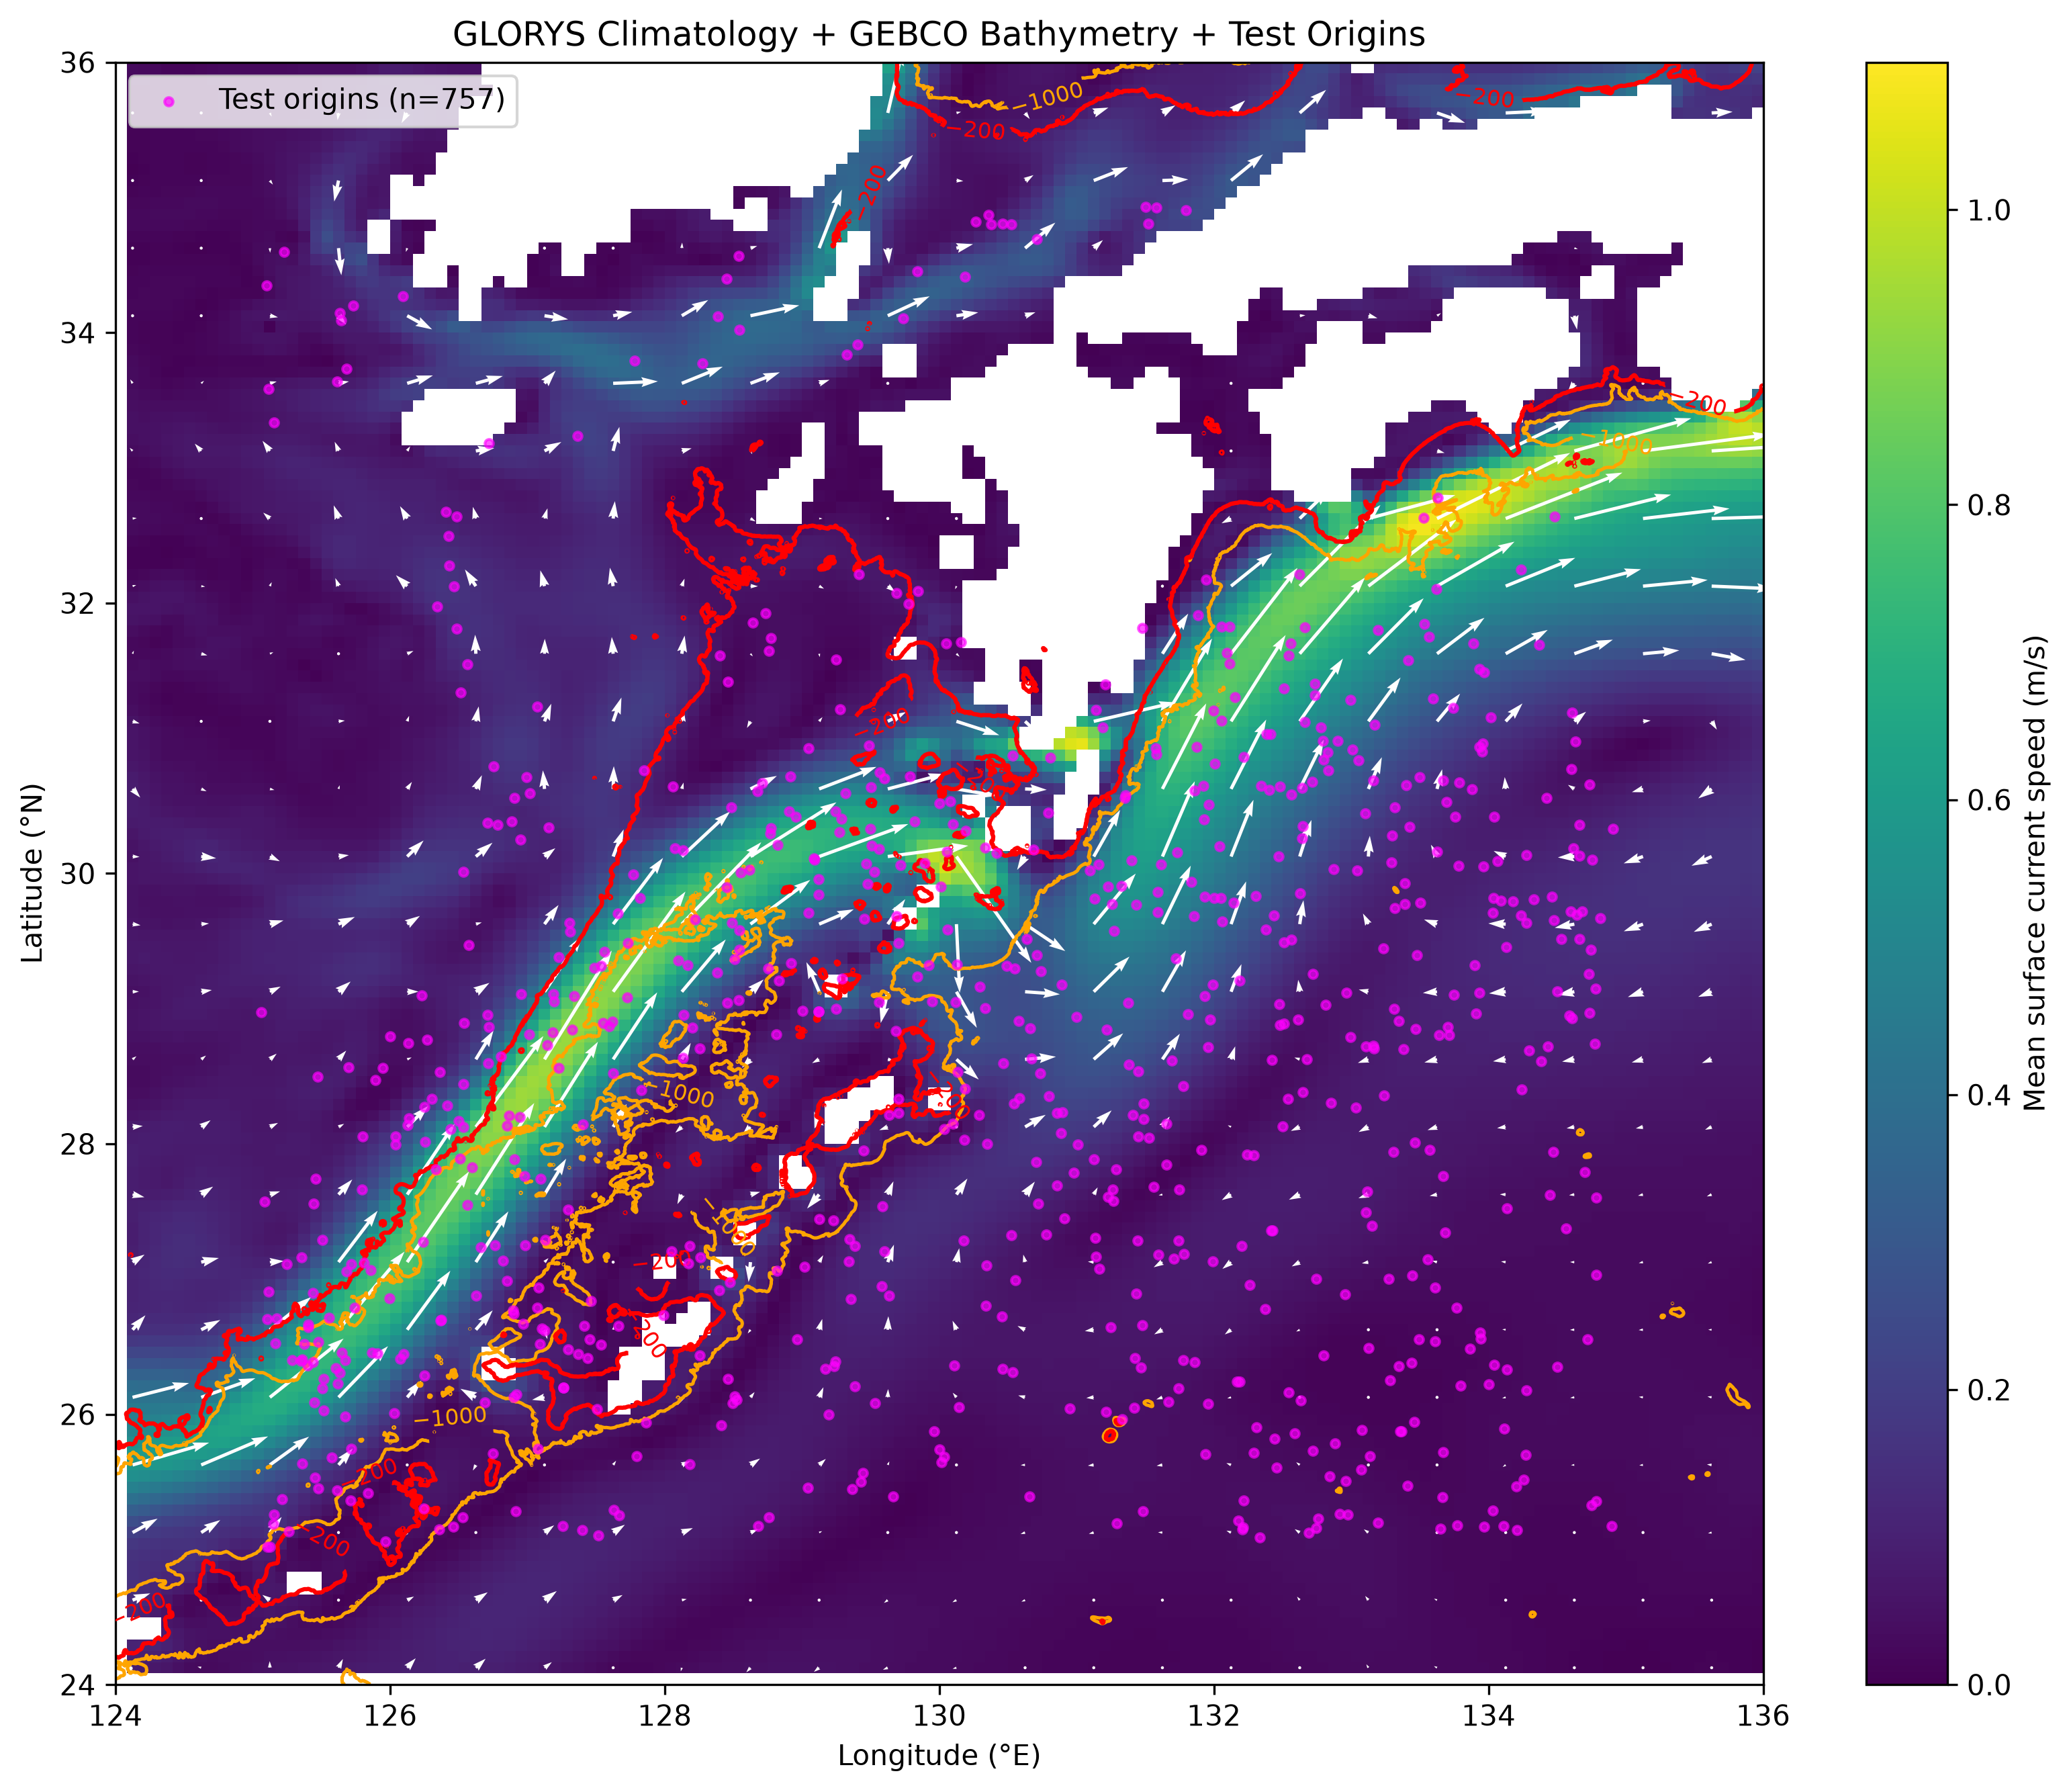

In [4]:
for filename, caption in [
    ("glorys_climatology_1994_2022.png", "GLORYS 1994–2022 mean surface-current climatology"),
    ("regime_overlay.png", "Bathymetry and climatological-current overlay"),
]:
    path = FIGURES / filename
    if path.exists():
        display(Markdown(f"**{caption}**"))
        display(Image(filename=str(path), width=760))
    else:
        print("Missing optional figure:", path)

## 5. Regime definition

Regimes are assigned in the following priority order:

1. **Kuroshio Core:** the two geographically verified, connected high-current components with climatological speed at least 0.5 m/s;
2. **Shelf:** not Core and water depth no greater than 200 m;
3. **Transition:** not Core/Shelf and either depth is 200–1000 m or distance to Core is no greater than 50 km;
4. **Other Offshore:** all remaining valid offshore cases.

Priority matters. For example, a high-current point above relatively shallow bathymetry remains Core rather than Shelf.

In [5]:
features = pd.read_csv(DATA / "forecast_case_kuroshio_features.csv")

valid = (
    features["depth_m"].notna()
    & features["depth_m"].ge(0)
    & features["current_speed_clim"].notna()
    & features["distance_to_kuroshio_km"].notna()
    & features["glorys_match_valid"].astype(bool)
)
core = valid & features["current_component_id"].isin([1, 2])
shelf = valid & ~core & features["depth_m"].le(200)
transition = (
    valid & ~core & ~shelf
    & (features["depth_m"].between(200, 1000, inclusive="right")
       | features["distance_to_kuroshio_km"].le(50))
)

recomputed = np.full(len(features), "Unclassified", dtype=object)
recomputed[core] = "Kuroshio Core"
recomputed[shelf] = "Shelf"
recomputed[transition] = "Transition"
recomputed[valid & ~core & ~shelf & ~transition] = "Other Offshore"

saved_regimes = pd.read_csv(DATA / "forecast_case_regimes.csv")
assert len(saved_regimes) == 5117
assert np.array_equal(recomputed, saved_regimes["regime"].to_numpy())
print("PASS: notebook regime rules reproduce all 5,117 saved labels.")

PASS: notebook regime rules reproduce all 5,117 saved labels.


In [6]:
test_regimes = saved_regimes.loc[saved_regimes["partition"].eq("test")].copy()
regime_counts = (
    test_regimes.groupby("regime")
    .agg(Cases=("forecast_case_id", "size"), Drifters=("ID", "nunique"))
    .reindex(REGIMES)
)
regime_counts["Percent of test cases"] = 100 * regime_counts["Cases"] / len(test_regimes)
display(regime_counts.style.format({"Percent of test cases": "{:.1f}%"}))

drifter_regime_n = test_regimes.groupby("ID")["regime"].nunique()
print(f"Test cases: {len(test_regimes)}")
print(f"Usable test drifters: {test_regimes['ID'].nunique()}")
print(f"Drifters represented in multiple regimes: {(drifter_regime_n > 1).sum()}")

,Cases,Drifters,Percent of test cases
regime,,,
Shelf,112,28,14.8%
Kuroshio Core,139,45,18.4%
Transition,165,43,21.8%
Other Offshore,341,41,45.0%


Test cases: 757
Usable test drifters: 71
Drifters represented in multiple regimes: 47


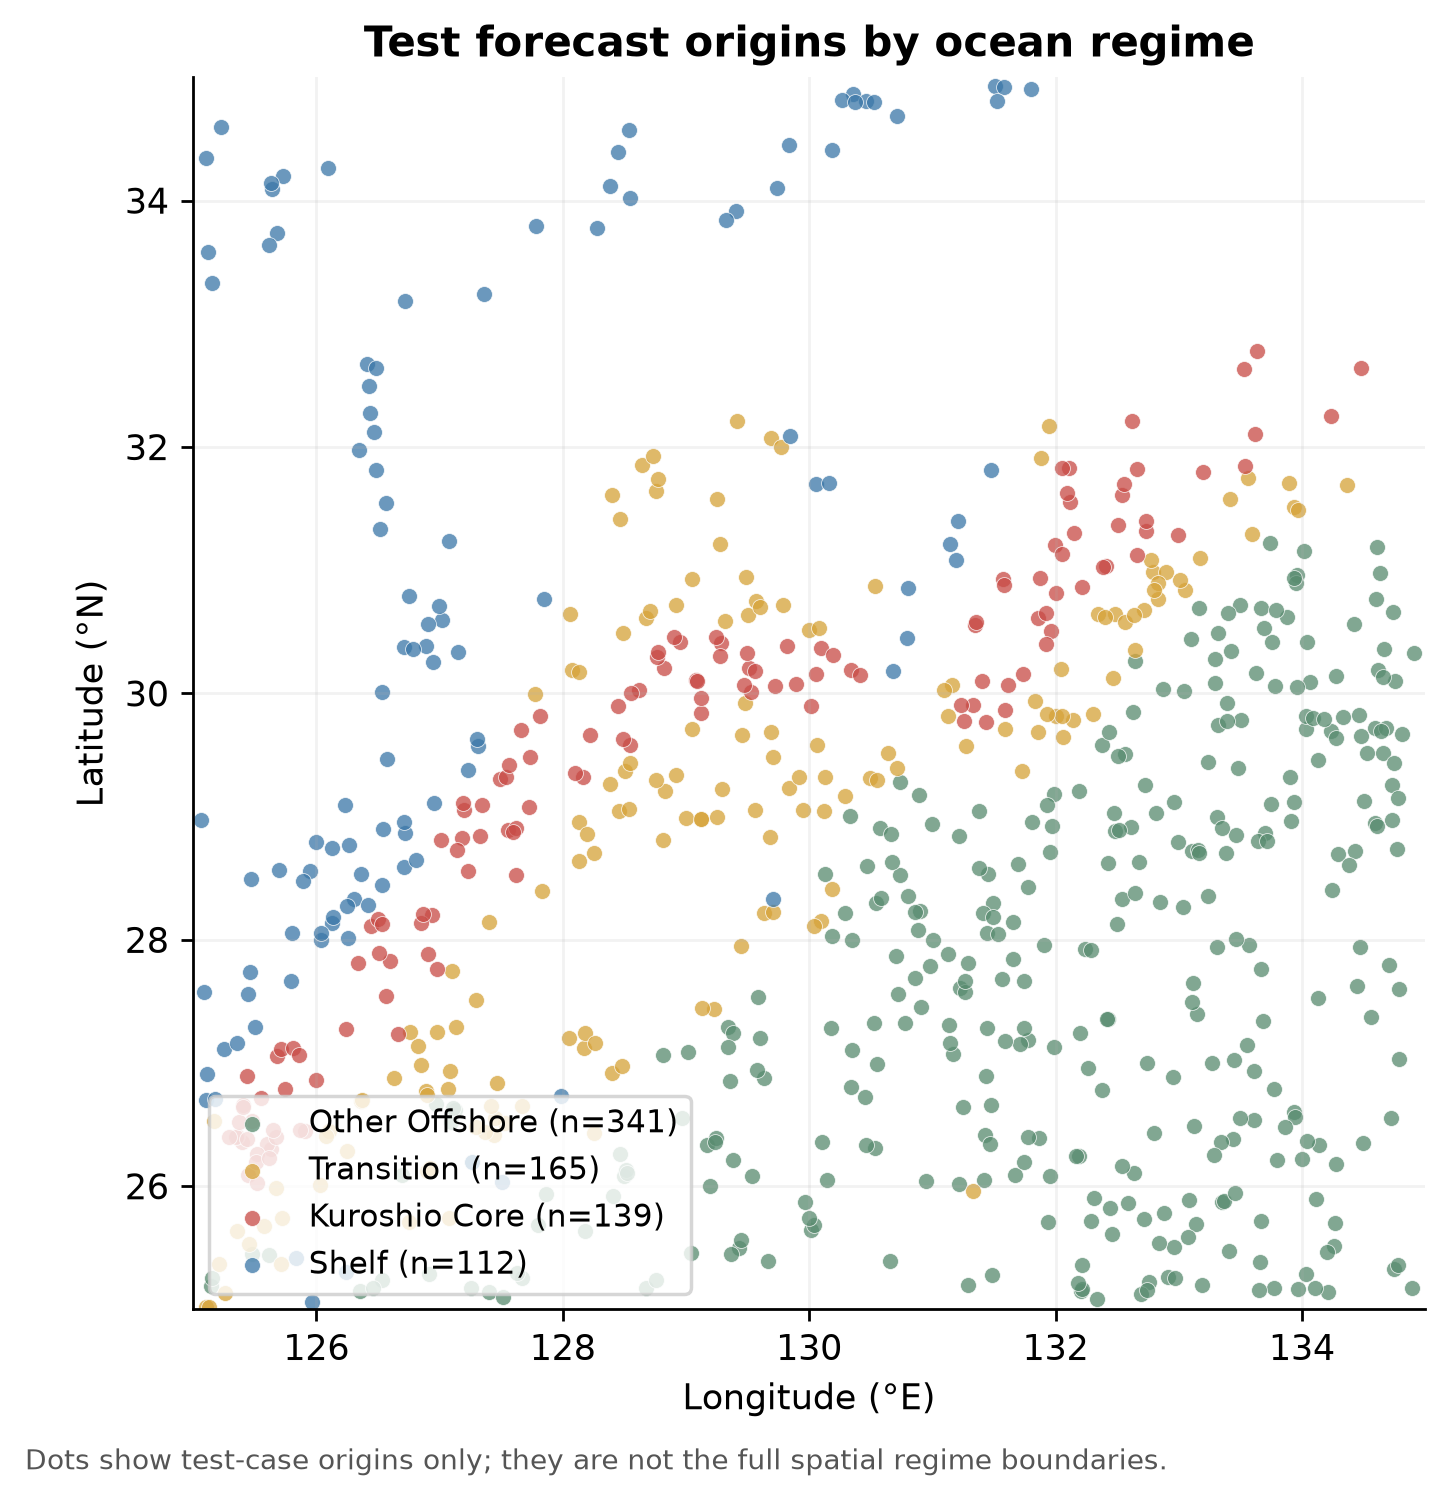

In [7]:
display(Image(filename=str(FIGURES / "17_fig1_test_origins_by_regime.png"), width=720))

## 6. Merge with frozen RQ1 prediction errors

No model is refitted for RQ2. The six models are evaluated on exactly the same 757 held-out cases:

- velocity persistence;
- spatial mean flow;
- pooled VAR(1);
- Ridge;
- Weighted KNN;
- FNN.

The primary RQ2 outcome is the 72-hour endpoint Haversine separation error. Mean trajectory error and integrated trajectory error remain available as secondary outcomes.

In [8]:
errors = pd.read_csv(DATA / "rq2_test_model_errors_long.csv")

assert len(errors) == 757 * 6
assert errors["forecast_case_id"].nunique() == 757
assert errors["ID"].nunique() == 71
assert errors.groupby("forecast_case_id")["model"].nunique().eq(6).all()

overall = (
    errors.groupby("model")
    .agg(
        cases=("forecast_case_id", "size"),
        median_72h_km=("final_72h_error_km", "median"),
        median_mean_trajectory_km=("mean_trajectory_error_km", "median"),
        median_ITE_km_h=("integrated_trajectory_error_km_h", "median"),
    )
    .reindex(MODELS)
)
overall["rmse_72h_km"] = errors.groupby("model")["final_72h_error_km"].apply(
    lambda x: np.sqrt(np.mean(np.square(x)))
).reindex(MODELS)
display(overall.round(2))

,cases,median_72h_km,median_mean_trajectory_km,median_ITE_km_h,rmse_72h_km
model,,,,,
Persistence,757,61.35,27.86,1962.45,90.10
Mean Flow,757,56.42,30.88,2201.71,80.98
Ridge,757,44.75,21.61,1531.79,65.91
FNN,757,41.72,20.13,1423.73,62.15
VAR(1),757,55.89,26.65,1894.78,77.89
KNN,757,41.99,20.59,1462.93,65.21


## 7. Regime-wise model performance

The next table shows the observed 72-hour endpoint metrics. These point estimates are case-weighted: a drifter contributing more forecast cases contributes more observations. Cluster bootstrap is used below so uncertainty accounts for within-drifter dependence.

In [9]:
regime_model = (
    errors.groupby(["regime", "model"])
    .agg(
        cases=("forecast_case_id", "size"),
        drifters=("ID", "nunique"),
        median_72h_km=("final_72h_error_km", "median"),
        rmse_72h_km=("final_72h_error_km", lambda x: np.sqrt(np.mean(np.square(x)))),
        median_ITE_km_h=("integrated_trajectory_error_km_h", "median"),
    )
    .reset_index()
)

median_table = regime_model.pivot(index="model", columns="regime", values="median_72h_km")
median_table = median_table.reindex(index=MODELS, columns=REGIMES)
display(Markdown("**Median 72-hour endpoint error (km; lower is better)**"))
display(median_table.round(2))

rmse_table = regime_model.pivot(index="model", columns="regime", values="rmse_72h_km")
rmse_table = rmse_table.reindex(index=MODELS, columns=REGIMES)
display(Markdown("**72-hour endpoint RMSE (km; lower is better)**"))
display(rmse_table.round(2))

**Median 72-hour endpoint error (km; lower is better)**

regime,Shelf,Kuroshio Core,Transition,Other Offshore
model,,,,
Persistence,46.30,83.32,69.74,56.60
Mean Flow,30.89,77.10,47.14,62.66
Ridge,32.66,66.66,45.97,43.70
FNN,25.69,64.08,41.08,40.60
VAR(1),33.79,91.38,47.15,58.39
KNN,26.79,67.44,41.41,40.05


**72-hour endpoint RMSE (km; lower is better)**

regime,Shelf,Kuroshio Core,Transition,Other Offshore
model,,,,
Persistence,75.54,120.36,91.73,78.56
Mean Flow,46.07,105.33,81.14,78.44
Ridge,46.35,92.08,68.75,56.53
FNN,41.61,87.48,66.19,52.60
VAR(1),46.34,111.47,76.19,69.91
KNN,40.22,92.66,68.74,55.88


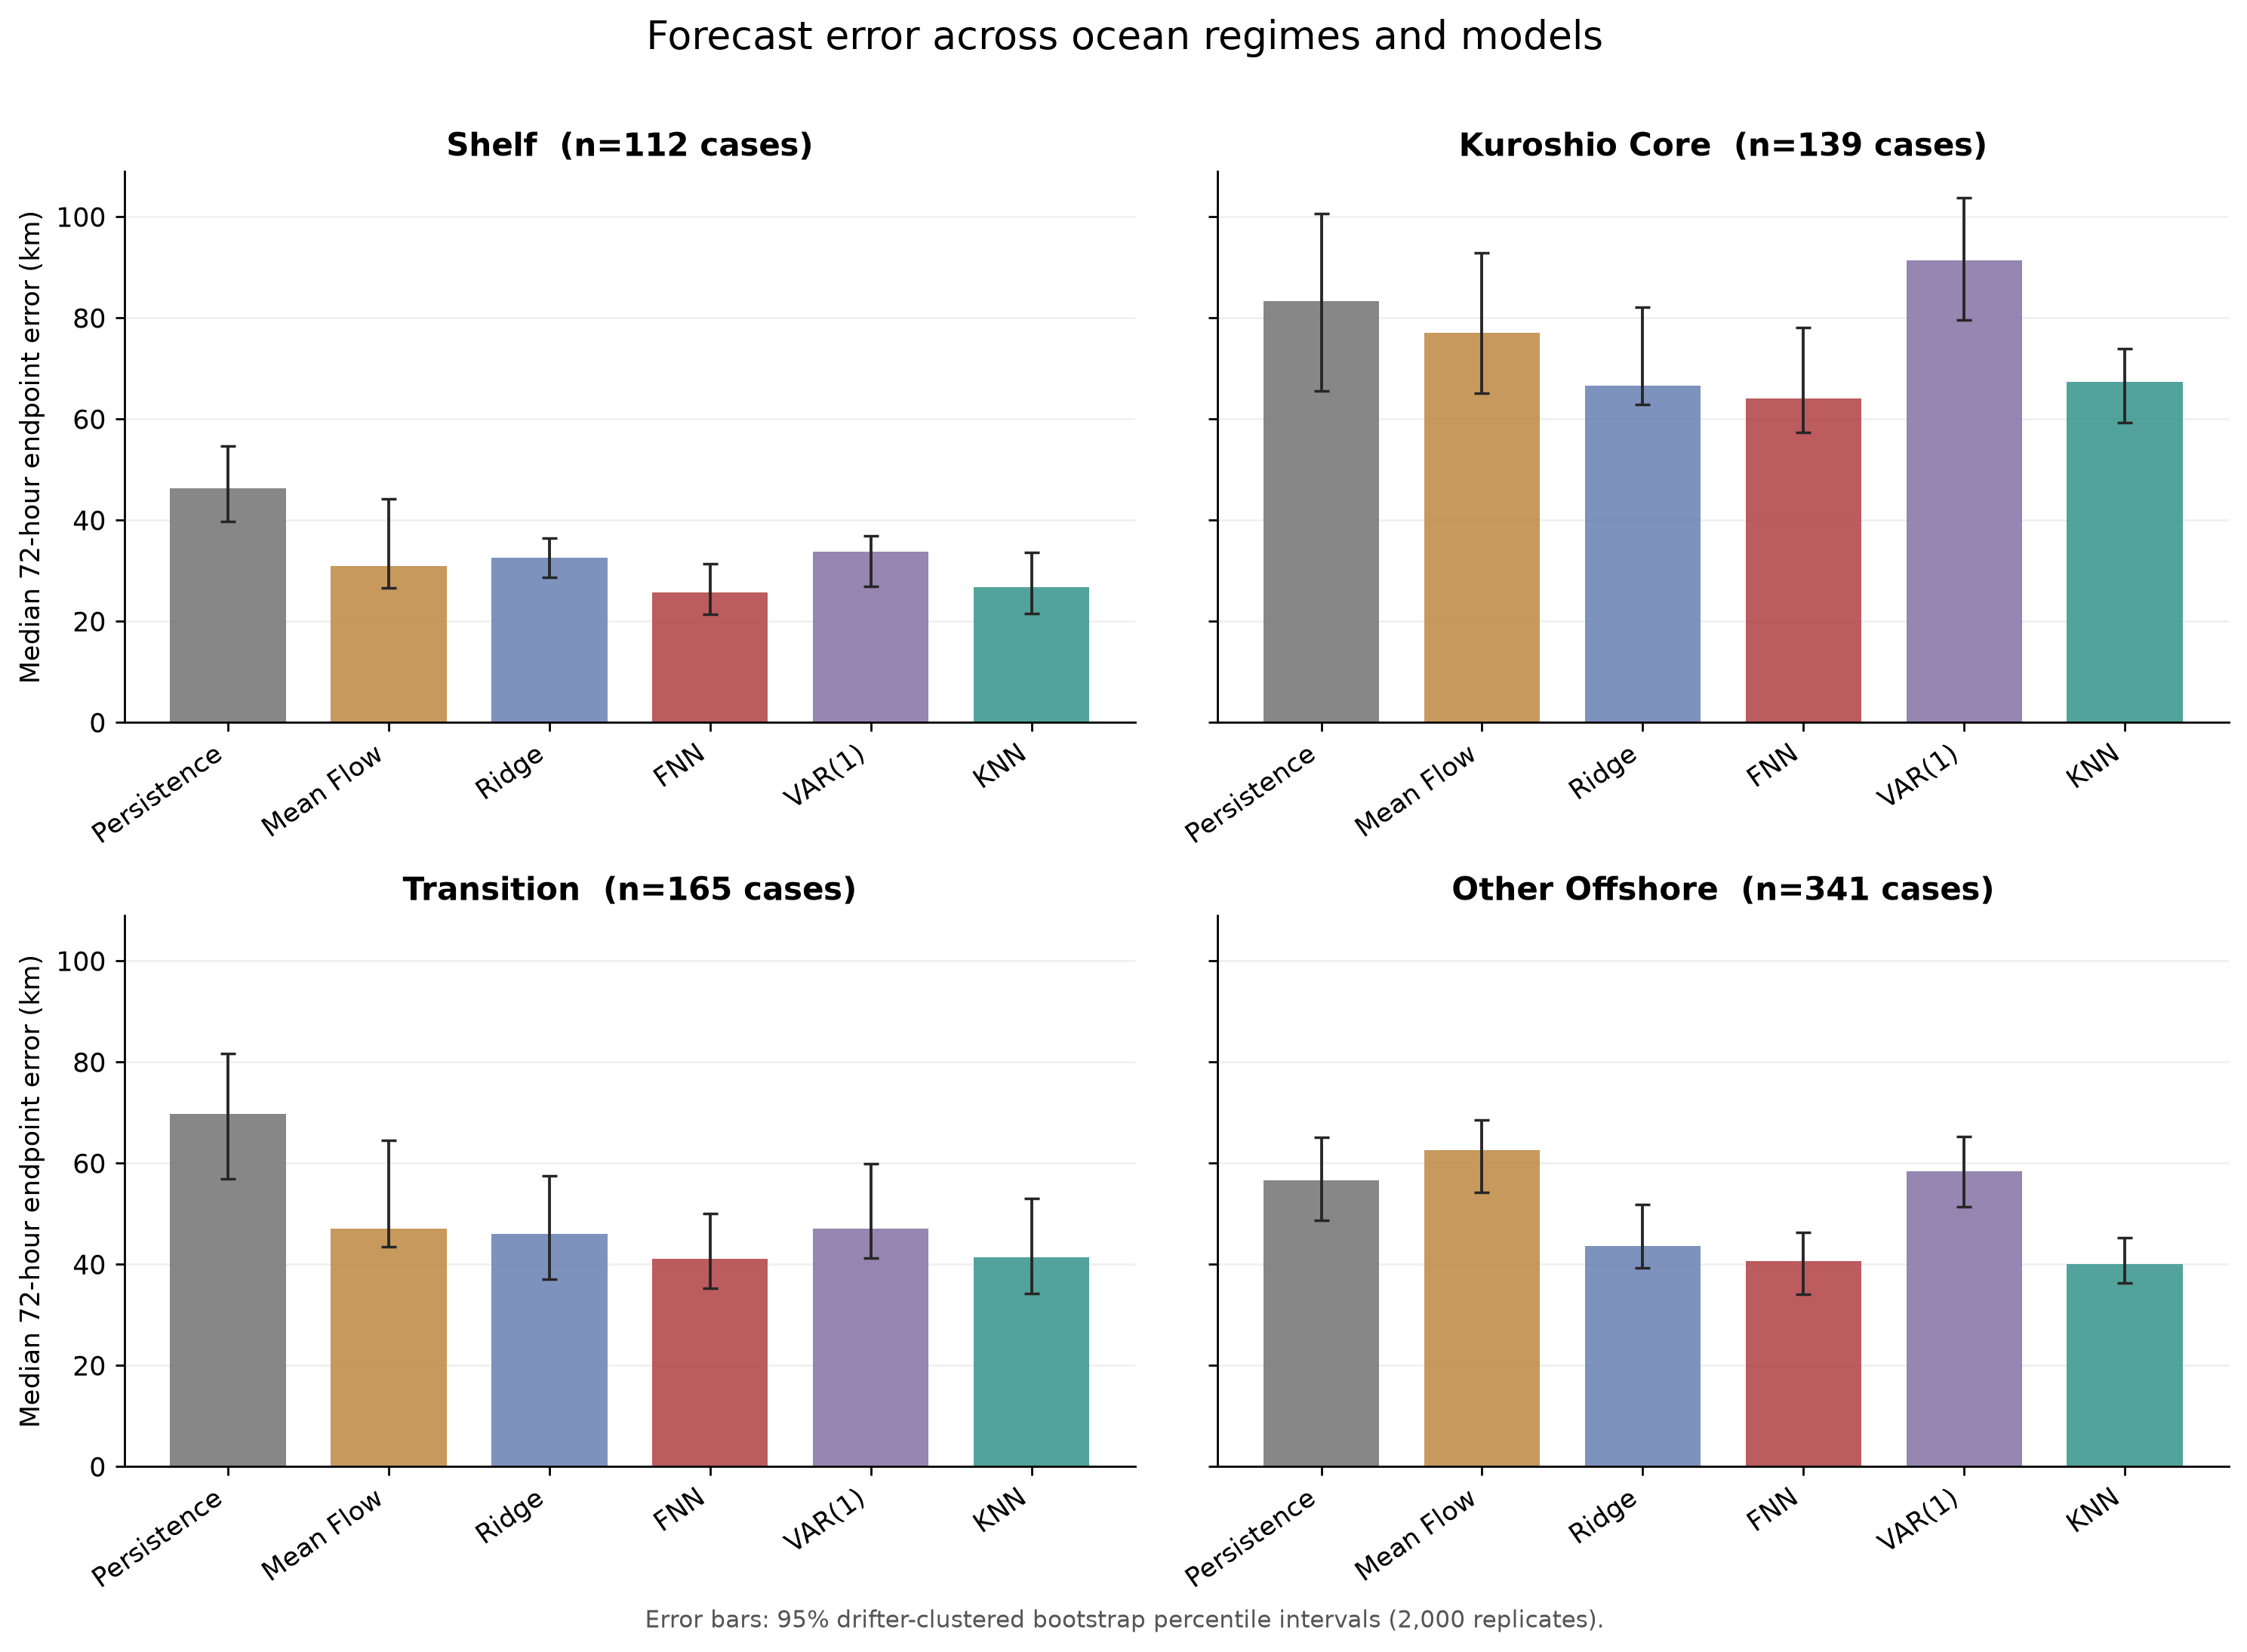

In [10]:
display(Image(filename=str(FIGURES / "17_fig2_model_error_by_regime.png"), width=980))

## 8. Drifter-clustered bootstrap

Cases from the same drifter are correlated. Therefore, the bootstrap resamples the **71 test drifters**, not individual cases. Whenever a drifter is selected, all of its forecast cases are carried into that replicate, including cases from multiple regimes.

For a statistic \(T\), replicate \(b\) is

\[
T^{*(b)} = T\bigl(\text{all cases belonging to the resampled drifters}\bigr).
\]

The reported 95% intervals are the 2.5th and 97.5th percentiles across 2,000 replicates. They are descriptive intervals without multiple-comparison correction.

In [11]:
bootstrap = pd.read_csv(DATA / "rq2_cluster_bootstrap_summary.csv")

fnn_bootstrap = (
    bootstrap.loc[bootstrap["model"].eq("FNN"), [
        "regime", "n_cases", "n_drifters", "median_72h_km",
        "median_ci_lower_km", "median_ci_upper_km",
        "rmse_72h_km", "rmse_ci_lower_km", "rmse_ci_upper_km"
    ]]
    .set_index("regime")
    .reindex(REGIMES)
)
display(fnn_bootstrap.round(2))

contrasts = pd.read_csv(DATA / "rq2_cluster_bootstrap_regime_contrasts.csv")
core_shelf = contrasts.loc[
    contrasts["model"].eq("FNN"),
    ["metric", "difference_km", "ci_lower_km", "ci_upper_km", "ci_excludes_zero"]
]
display(Markdown("**FNN: Kuroshio Core minus Shelf**"))
display(core_shelf.round(2).style.hide(axis="index"))

,n_cases,n_drifters,median_72h_km,median_ci_lower_km,median_ci_upper_km,rmse_72h_km,rmse_ci_lower_km,rmse_ci_upper_km
regime,,,,,,,,
Shelf,112,28,25.69,21.41,31.35,41.61,33.26,53.47
Kuroshio Core,139,45,64.08,57.42,78.06,87.48,78.69,96.72
Transition,165,43,41.08,35.32,50.13,66.19,56.36,76.82
Other Offshore,341,41,40.60,34.11,46.41,52.60,48.16,57.47


**FNN: Kuroshio Core minus Shelf**

metric,difference_km,ci_lower_km,ci_upper_km,ci_excludes_zero
median,38.390000,29.850000,52.730000,True
rmse,45.860000,32.030000,58.280000,True


## 9. Paired model advantage

For each test case, FNN advantage over comparator \(m\) is

\[
A_{i,m}=e_{i,m}-e_{i,\mathrm{FNN}}.
\]

- Positive advantage: FNN has the smaller error.
- Zero: equal error.
- Negative advantage: the comparator has the smaller error.

This case-paired construction is more informative than comparing unrelated group averages because both predictions refer to the same initial condition and observed target.

In [12]:
advantage = pd.read_csv(DATA / "rq2_model_advantage_by_regime.csv")

advantage_table = advantage.pivot(
    index="regime", columns="comparator", values="mean_advantage_km"
).reindex(index=REGIMES, columns=["Persistence", "Mean Flow", "Ridge", "VAR(1)", "KNN"])
display(Markdown("**Mean paired advantage in km (positive favours FNN)**"))
display(advantage_table.round(2))

fnn_vs_knn = advantage.loc[
    advantage["comparator"].eq("KNN"),
    ["regime", "mean_advantage_km", "ci_lower_km", "ci_upper_km", "ci_excludes_zero"]
].set_index("regime").reindex(REGIMES)
display(Markdown("**FNN versus Weighted KNN**"))
display(fnn_vs_knn.round(2))

**Mean paired advantage in km (positive favours FNN)**

comparator,Persistence,Mean Flow,Ridge,VAR(1),KNN
regime,,,,,
Shelf,27.21,5.91,6.28,5.56,0.15
Kuroshio Core,24.88,14.80,4.08,23.57,3.01
Transition,24.56,11.14,2.93,8.69,1.11
Other Offshore,21.64,23.58,3.97,17.36,2.67


**FNN versus Weighted KNN**

,mean_advantage_km,ci_lower_km,ci_upper_km,ci_excludes_zero
regime,,,,
Shelf,0.15,-3.44,4.50,False
Kuroshio Core,3.01,-0.71,6.17,False
Transition,1.11,-1.38,3.68,False
Other Offshore,2.67,1.27,4.12,True


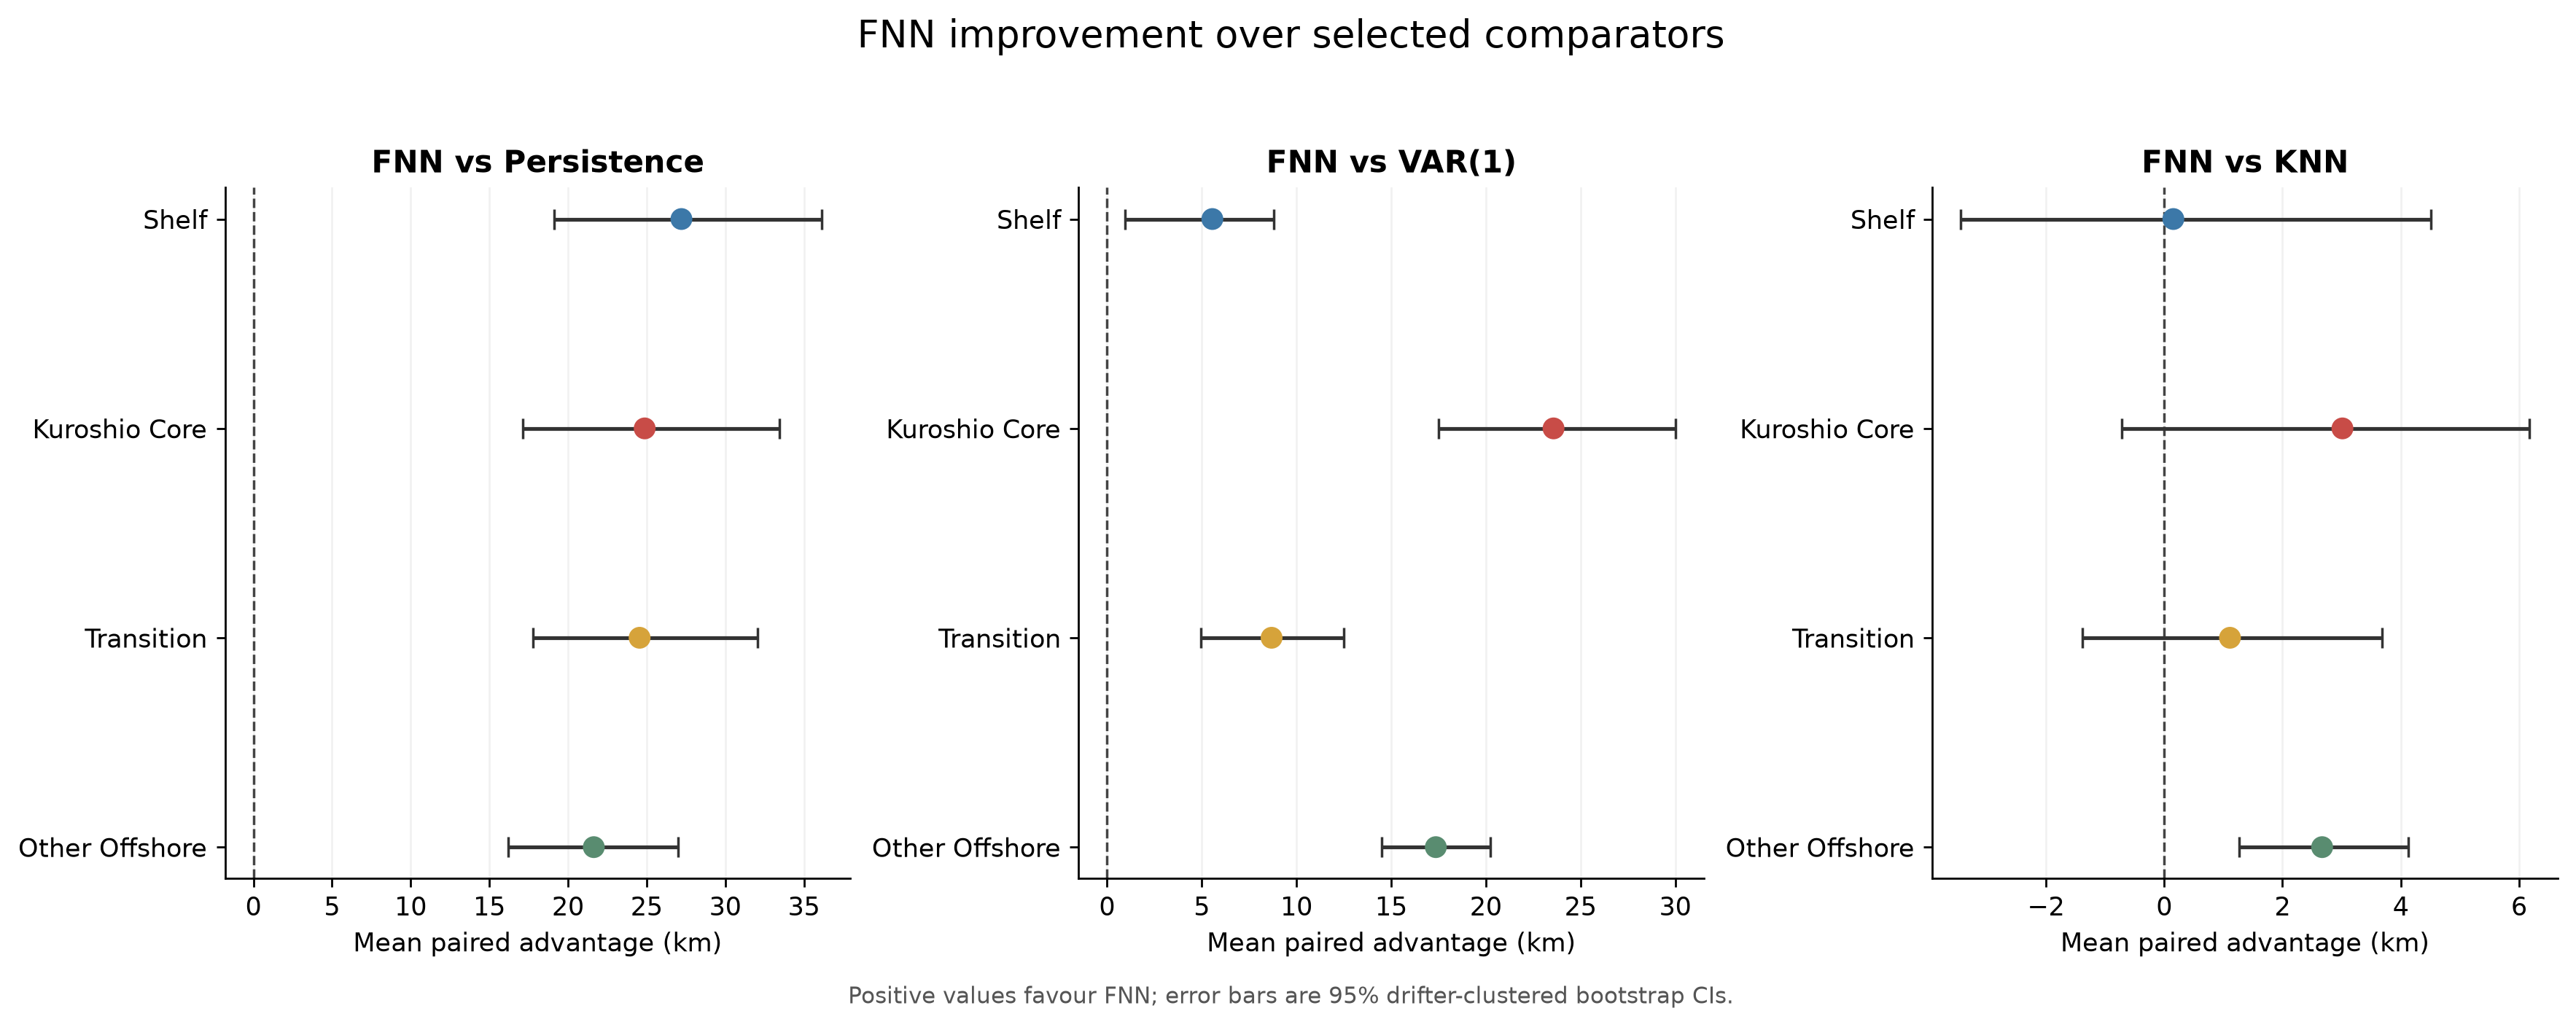

In [13]:
display(Image(filename=str(FIGURES / "17_fig3_fnn_paired_advantage.png"), width=1050))

## 10. Does the relative model advantage change by regime?

The interaction analysis compares the mean paired advantage in each regime with the Shelf advantage. A confidence interval crossing zero means the data do not clearly establish a change relative to Shelf.

In [14]:
interactions = pd.read_csv(DATA / "rq2_model_advantage_regime_contrasts.csv")
interaction_view = interactions[[
    "comparator", "contrast", "difference_in_mean_advantage_km",
    "ci_lower_km", "ci_upper_km", "ci_excludes_zero"
]]
display(interaction_view.round(2).style.hide(axis="index"))

comparator,contrast,difference_in_mean_advantage_km,ci_lower_km,ci_upper_km,ci_excludes_zero
Persistence,Kuroshio Core minus Shelf,-2.340000,-13.020000,8.420000,False
Persistence,Transition minus Shelf,-2.660000,-13.580000,7.760000,False
Persistence,Other Offshore minus Shelf,-5.570000,-15.690000,4.520000,False
Mean Flow,Kuroshio Core minus Shelf,8.890000,-2.780000,19.400000,False
Mean Flow,Transition minus Shelf,5.220000,-2.820000,13.080000,False
Mean Flow,Other Offshore minus Shelf,17.660000,10.630000,24.060000,True
Ridge,Kuroshio Core minus Shelf,-2.200000,-6.210000,2.590000,False
Ridge,Transition minus Shelf,-3.350000,-6.870000,0.910000,False
Ridge,Other Offshore minus Shelf,-2.300000,-5.380000,1.730000,False
VAR(1),Kuroshio Core minus Shelf,18.020000,11.280000,25.350000,True


## 11. Sensitivity to the Kuroshio speed threshold

The principal definition uses 0.5 m/s. The sensitivity analysis repeats the classification using 0.4, 0.5 and 0.6 m/s and transition buffers of 25, 50 and 75 km.

Buffer distance changes Transition/Other Offshore membership but does not alter Core or Shelf membership, so the Core–Shelf contrast is repeated across buffers.

In [15]:
sensitivity = pd.read_csv(DATA / "rq2_sensitivity_core_shelf_contrasts.csv")
fnn_sensitivity = sensitivity.loc[
    sensitivity["model"].eq("FNN") & sensitivity["metric"].eq("median"),
    ["speed_threshold_m_s", "buffer_km", "core_minus_shelf_km",
     "ci_lower_km", "ci_upper_km", "ci_excludes_zero"]
]
display(fnn_sensitivity.round(2).style.hide(axis="index"))

speed_threshold_m_s,buffer_km,core_minus_shelf_km,ci_lower_km,ci_upper_km,ci_excludes_zero
0.400000,25,38.750000,31.530000,52.180000,True
0.400000,50,38.750000,31.530000,52.180000,True
0.400000,75,38.750000,31.530000,52.180000,True
0.500000,25,38.390000,30.310000,52.990000,True
0.500000,50,38.390000,30.310000,52.990000,True
0.500000,75,38.390000,30.310000,52.990000,True
0.600000,25,38.790000,29.500000,53.440000,True
0.600000,50,38.790000,29.500000,53.440000,True
0.600000,75,38.790000,29.500000,53.440000,True


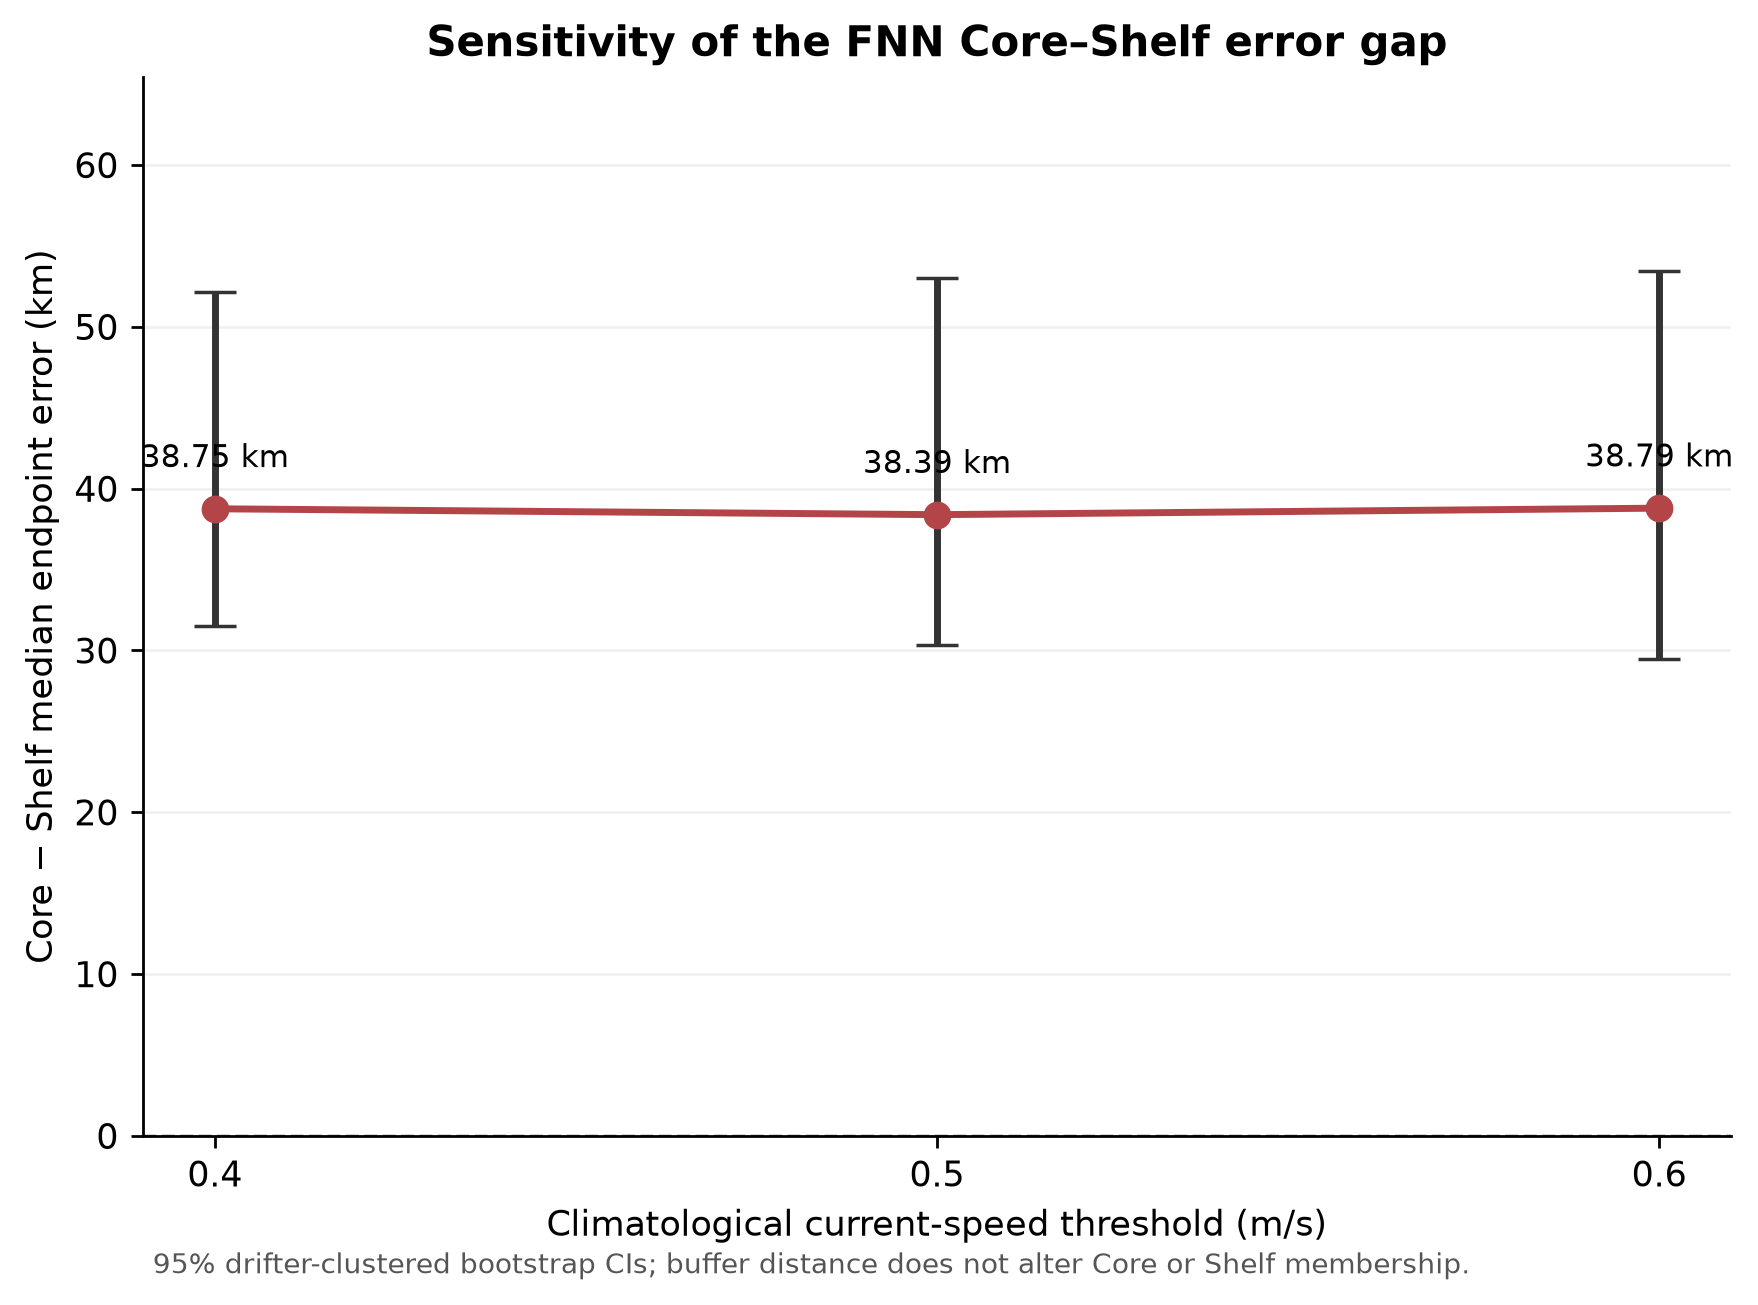

In [16]:
display(Image(filename=str(FIGURES / "17_fig4_core_shelf_threshold_sensitivity.png"), width=760))

## 12. Main answers to RQ2

### Finding 1 — Absolute difficulty differs strongly by regime

FNN median 72-hour endpoint error increases from **25.69 km on the Shelf** to **64.08 km in the Kuroshio Core**. The Core–Shelf difference is **38.39 km**, with a drifter-clustered 95% interval of approximately **29.85–52.73 km**.

### Finding 2 — FNN still improves substantially over persistence

FNN's mean paired improvement over velocity persistence is approximately **21.6–27.2 km** across the four regimes, and all four intervals exclude zero.

### Finding 3 — FNN and Weighted KNN are often statistically similar

The FNN–KNN advantage interval crosses zero on the Shelf, in the Kuroshio Core and in Transition waters. Only Other Offshore shows a small clearly positive mean FNN advantage.

### Careful interpretation

The analysis supports **regime-dependent absolute forecast error**. It does not by itself prove that the Kuroshio causes forecast failure, because faster flow and longer travelled distances naturally increase kilometre-scale error. Forecast skill relative to a baseline or error normalised by travelled distance would strengthen the predictability interpretation.

## 13. Limitations and checks before final reporting

1. **Endpoint-only emphasis:** the primary figures focus on the 72-hour endpoint; ITE or lead-time curves would better represent the full trajectory.
2. **Climatological labels:** regime labels describe long-term mean circulation, not the instantaneous current at the forecast date.
3. **Absolute error versus predictability:** larger Core errors may partly reflect greater displacement rather than uniquely lower dynamical predictability.
4. **Threshold selection:** candidate thresholds were inspected using test-set sample counts. A stricter confirmatory analysis would select thresholds using external oceanographic criteria or training/calibration data only.
5. **Case weighting:** point estimates weight forecast cases, so drifters contributing many cases have more influence. A per-drifter aggregation can be added as sensitivity analysis.
6. **Multiple comparisons:** bootstrap intervals are uncorrected; broad claims across many model–regime comparisons should remain descriptive.
7. **Counts:** distinguish 79 assigned test drifters from 71 test drifters with usable cases.

## 14. Optional recomputation controls

The following cell is disabled by default. Change a flag to `True` only when you intentionally want to overwrite the corresponding saved CSVs and figures.

- `RUN_REGIME_STAGES`: recompute the prepared environmental assignment and regime labels from existing derived inputs.
- `RUN_STATISTICAL_STAGES`: rerun 2,000-replicate bootstrap analyses and redraw final figures.

Stage 14 is omitted because the six separate RQ1 case-metric files are not currently present; the saved merged file is used instead.

In [17]:
import subprocess

RUN_REGIME_STAGES = False
RUN_STATISTICAL_STAGES = False

def run_script(relative_path):
    path = PROJECT / relative_path
    print(f"\n>>> Running {path.relative_to(PROJECT)}")
    subprocess.run([os.sys.executable, str(path)], cwd=PROJECT, check=True)

if RUN_REGIME_STAGES:
    for script in [
        "RQ2/11_assign_ocean_features.py",
        "RQ2/12c_identify_kuroshio_components.py",
        "RQ2/12d_assign_kuroshio_features.py",
        "RQ2/13_define_ocean_regimes.py",
    ]:
        run_script(script)

if RUN_STATISTICAL_STAGES:
    for script in [
        "RQ2/15_cluster_bootstrap.py",
        "RQ2/16a_model_advantage_by_regime.py",
        "RQ2/16b_regime_sensitivity.py",
        "RQ2/17_final_figures.py",
    ]:
        run_script(script)

if not RUN_REGIME_STAGES and not RUN_STATISTICAL_STAGES:
    print("Safe mode: no files were overwritten. Set a flag to True to recompute outputs.")

Safe mode: no files were overwritten. Set a flag to True to recompute outputs.


## 15. Original script map

| Stage | Purpose |
|---|---|
| 01–02 | Check forecast cases and plot origins |
| 03–05 | Inspect and assign GEBCO bathymetry |
| 06–09 | Inspect/download GLORYS and build 1994–2022 climatology |
| 10–13 | Overlay environmental data, identify Kuroshio components and assign regimes |
| 14 | Merge frozen RQ1 test-case errors with regime labels |
| 15 | Drifter-clustered bootstrap |
| 16A | Paired FNN advantages and regime interactions |
| 16B | Regime-definition sensitivity analysis |
| 17 | Publication-ready final figures |

The original scripts remain in `RQ2/` for traceability. This notebook is the recommended entry point for reading, explaining and selectively rerunning the analysis.